In [ ]:
# Cplex version, exceed max nb of variables in docplex if T or P is too large
import sys
sys.path.append('C:\\Program Files\\IBM\\ILOG\\CPLEX_Studio210\\cplex\\python\\20.1\\x64_win64')
sys.path.append("C:\\ProgramData\\anaconda3\\Lib\\site-packages")
import numpy as np
import pandas as pd
from docplex.mp.model import Model
import matplotlib.pyplot as plt
import random

# define the parameters
PARAMS = {
    'P': 10,        # number of caissons
    'T': 30,      # horizon
    'Cmax':5,      # maximum number of tasks of one cluster
    'window_size': 10,   # window size
    'advanced': 3,          # advanced time
    'K': 5.993,         # leakage coefficient
    'alpha': 5,    # unit cost of advancing one day
    'beta': 10,       # unit cost of delaying one day
    'Cs':100      # Unit setup cost
}   

# initialize the random values
random.seed(42)
# alpha_values = [round(random.uniform(0.03, 0.08), 3) for _ in range(PARAMS['P'])]
alpha_values = [round(random.uniform(0.01, 0.05), 3) for _ in range(PARAMS['P'])]   # degradation rate for each caisson
initial_p_values = [round(random.uniform(3.2, 3.5), 2) for i in range(PARAMS['P'])]
print("alpha values:", alpha_values)

def calculate_maintenance_period_from_data(df, d_min_ratio=0.6, d_max_ratio=1.4):
    """extract maintenance periods from data"""
    
    maintenance_periods = {}
    D_min_dict = {}
    D_max_dict = {}
    
    print("\n===== 从数据中提取维修周期 =====")
    print(f"{'Caisson':<10} {'间隔数':<10} {'间隔范围':<20} {'周期':<12} {'D_min':<10} {'D_max':<10}")
    print("-" * 80)
    
    for caisson_id in sorted(df['CSEM'].unique()):
        # 步骤1：筛选该caisson的所有'x'操作
        caisson_tasks = df[
            (df['CSEM'] == caisson_id) & 
            (df['OPERATION'] == 'x')
        ].sort_values('DATE')
        
        # Step 2: Check if there are at least 2 tasks
        if len(caisson_tasks) < 2:
            default_period = PARAMS['window_size']  # ← 新增
            maintenance_periods[caisson_id] = default_period
            D_min_dict[caisson_id] = int(np.ceil(default_period * d_min_ratio))
            D_max_dict[caisson_id] = int(np.ceil(default_period * d_max_ratio))
            print(f"... {default_period:<12.2f} ...")  
            continue
        
        # 步骤3：计算相邻任务之间的间隔
        intervals = []
        for i in range(1, len(caisson_tasks)):
            interval = caisson_tasks.iloc[i]['DATE'] - caisson_tasks.iloc[i-1]['DATE']
            intervals.append(interval)
        
        # 步骤4：使用中位数作为维修周期
        maintenance_period = np.mean(intervals)
        maintenance_periods[caisson_id] = maintenance_period
        
        # 步骤5：计算D_min和D_max
        D_min_dict[caisson_id] = int(np.ceil(maintenance_period * d_min_ratio))
        D_max_dict[caisson_id] = int(np.ceil(maintenance_period * d_max_ratio))
        
        # 步骤6：打印结果
        interval_min = min(intervals)
        interval_max = max(intervals)
        interval_range = f"[{interval_min}, {interval_max}]"
        
        print(f"{caisson_id:<10} {len(intervals):<10} {interval_range:<20} "
              f"{maintenance_period:<12.2f} {D_min_dict[caisson_id]:<10} {D_max_dict[caisson_id]:<10}")
    
    print("===== 提取完成 =====\n")
    
    return maintenance_periods, D_min_dict, D_max_dict

# function to group the tasks within a window
def clustering_CR(df_window, window_size, window_start, global_task_count, full_df, D_min_dict, D_max_dict):
    """Grouping model"""
    # add preprocessing here
    if df_window.empty or window_size < 1:
        print(f"warning: window {window_start} has no tasks or window size is invalid")
        return df_window  # return the original dataframe if no tasks in the window

    N = df_window.shape[0]  # number of tasks in the window

    mdl = Model('Dynamic_Window_Clustering')
    
    # define the variables
    data_pos_num = window_size + 1
    theta = mdl.binary_var_matrix(N, data_pos_num, name='theta')
    CS = mdl.continuous_var_list(data_pos_num, lb=0, name='CS')
    y = mdl.binary_var_list(data_pos_num, lb=0, name='y')
    # CP = mdl.integer_var_list(data_pos_num, lb=0, name='CP')
    # Delta = mdl.integer_var_list(N, name='Delta')
    # u = mdl.integer_var_list(N, name='u')
    # v = mdl.integer_var_list(N, name='v')

   


    a = [0] * N
    b = [0] * N
   

    # every task must be assigned to one cluster
    mdl.add_constraints(mdl.sum(theta[n, t] for t in range(data_pos_num)) == 1 for n in range(N))
    
    # maximum capacity in each cluster
    mdl.add_constraints(mdl.sum(theta[n, t] for n in range(N)) <= PARAMS['Cmax'] for t in range(data_pos_num))

    # define the possible advanced or delayed range for each task: local time
    for n in range(N):
        local_time = int(df_window.iloc[n]['window_time'])
        a[n] = int(max(0, local_time - PARAMS['advanced']))
        b[n] = int(min(data_pos_num, local_time + int((3.2 - 3.0)/alpha_values[int(df_window.iloc[n]["CSEM"])]) - 2))
    
    # cluster center constraints
    for n in range(N):
        for t in range(data_pos_num):
            mdl.add_constraint(t * theta[n,t] + a[n] * (1 - theta[n, t]) >= a[n])
            mdl.add_constraint(t * theta[n,t] + b[n] * (1 - theta[n, t]) <= b[n])



    # 验证成功后，替换为完整版
    for t in range(data_pos_num):
        task_count = mdl.sum(theta[n,t] for n in range(N))
        M = PARAMS['Cmax']
        mdl.add_constraint(task_count >= 1 - M * (1 - y[t]))
        mdl.add_constraint(task_count <= M * y[t])

    setup_cost = PARAMS['Cs'] * (mdl.sum(mdl.sum(theta[n,t] for n in range(N)) for t in range(data_pos_num)) - mdl.sum(y))
    


    # 🔥 方案1修正版：常数矩阵 + 不对称成本
    cost_matrix = {}
    for n in range(N):
        local_time_n = int(df_window.iloc[n]['window_time'])
        for t in range(data_pos_num):
            deviation = t - local_time_n  # 注意：t - local_time (有正负)
            if deviation > 0:  # 延后，用beta
                cost_matrix[(n, t)] = PARAMS['beta'] * deviation
            elif deviation < 0:  # 提前，用alpha  
                cost_matrix[(n, t)] = PARAMS['alpha'] * (-deviation)  # -deviation > 0
            else:  # deviation == 0
                cost_matrix[(n, t)] = 0
    
    # 总偏差成本（完全线性！）
    CP_total = mdl.sum(
        cost_matrix[(n, t)] * theta[n, t] 
        for n in range(N) 
        for t in range(data_pos_num))


    # test test test
    # 🔥 修复：第一个窗口完全跳过维护约束
    for n in range(N):
        row = df_window.iloc[n]
        caisson = int(row['CSEM'])
        
        # 🔥 关键：第一个窗口完全跳过！
        if window_start == 0:
            print(f"  Caisson {caisson}: skip constraint (first window)")
            continue
            
        # 查找历史任务（仅后续窗口）
        prev_rows = full_df[
            (full_df['CSEM'] == caisson) &
            (full_df['CENTER'] < row['DATE']) &
            (full_df['OPERATION'] == 'x')
        ].sort_values('CENTER')
        
        if prev_rows.empty:
            prev_center = 0
            print(f"  Caisson {caisson}: first task ever, prev_center=0")
            continue  # 没有历史任务也跳过
        
        prev_center = int(prev_rows.iloc[-1]['CENTER'])
        print(f"  Caisson {caisson}: prev_center={prev_center}")
        
        # 当前任务时间
        t_now_local = mdl.sum(t * theta[n, t] for t in range(data_pos_num))
        t_now_global = t_now_local + window_start
        
        # 后续窗口使用原始D_min/D_max（不放宽）
        d_min_i = D_min_dict[caisson]
        d_max_i = D_max_dict[caisson]
        
        mdl.add_constraint(t_now_global - prev_center >= d_min_i)
        mdl.add_constraint(t_now_global - prev_center <= d_max_i)

    


    # objective function
    mdl.maximize(setup_cost - CP_total)


    # new  --
    print(f"Model stats: {mdl.number_of_variables} vars, {mdl.number_of_constraints} cons")
    print(f"Objective sense: {mdl.objective_sense}")
    mdl.print_information()


    # solve the model
    solution = mdl.solve()



    if not solution:
        print(f"Failed to solve the problem: {mdl.solve_details.status}")
        return None
    
    # result processing
    # convert local time back to original time and get the center for each task
    centers = {}
    for n in range(N):
            for t in range(data_pos_num):
                if solution.get_value(theta[n, t]) == 1.0:  # find the center for each cluster
                    # print(f"Task {n} (CSEM={df_window.iloc[n]['CSEM']}) assigned to cluster {t + window_start}")
                    centers[n] = t + window_start  # change the time back to the original time
                    break

    index_n_list = df_window.INDEX.tolist()

    for n in range(len(index_n_list)):
        for t in range(data_pos_num):
            if solution.get_value(theta[n, t]) == 1.0:
                df_window.loc[df_window['INDEX'] == index_n_list[n], 'CENTER'] = centers.get(n, 0)

    return df_window

# function to calculate the gas leakage before clustering
def calculate_gas_leakage_before(df, T):
    total_leakage = 0


    for csem in df['CSEM'].unique():
        # filter the data for the current CSEM
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x']
        y_operations = csem_data[csem_data['OPERATION'] == 'y']
        alpha = alpha_values[csem]


        # deal with the 'x' operations in the middle
        for i in range(1, len(x_operations)):
            current_x = x_operations.iloc[i]
            previous_x = x_operations.iloc[i - 1]
            center_diff = current_x['DATE'] - previous_x['DATE'] - 1
            total_leakage += center_diff * alpha * PARAMS['K']


        # deal with the first 'x' operation
        if not x_operations.empty:
            first_x = x_operations.iloc[0]
            total_leakage += first_x['DATE'] * alpha * PARAMS['K']

        # # deal with the last 'x' operation
        # last_x = x_operations.iloc[-1]
        # if not y_operations.empty:
        #     # if there is a 'y' operation
        #     y_center = y_operations['DATE'].iloc[0]
        #     total_leakage += (y_center - last_x['DATE']) * alpha * PARAMS['K']
        # else:
        #     # if there is no 'y' operation
        #     total_leakage += (T - last_x['DATE'] - 1) * alpha * PARAMS['K']

        # deal with the last 'x' operation (special handling)
        last_x = x_operations.iloc[-1]
        last_x_end = last_x['DATE'] + 1  # end of last maintenance day
        
        if not y_operations.empty:
            # if there is a 'y' operation
            y_center = y_operations['DATE'].iloc[0]
            leak_time = max(0, y_center - last_x_end)
            total_leakage += leak_time * alpha * PARAMS['K']
        else:
            # if there is no 'y' operation
            leak_time = max(0, T - last_x_end)
            total_leakage += leak_time * alpha * PARAMS['K']


    return total_leakage

# function to calculate the gas leakage after clustering
def calculate_gas_leakage_after(df, T):
    total_leakage = 0

    for csem in df['CSEM'].unique():
        # filter the data for the current CSEM
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x']
        y_operations = csem_data[csem_data['OPERATION'] == 'y']
        alpha = alpha_values[csem]

        # deal with the 'x' operations in the middle
        for i in range(1, len(x_operations)):
            current_x = x_operations.iloc[i]
            previous_x = x_operations.iloc[i - 1]
            center_diff = current_x['CENTER'] - previous_x['CENTER'] - 1
            total_leakage += center_diff * alpha * PARAMS['K']

        # deal with the first 'x' operation
        if not x_operations.empty:
            first_x = x_operations.iloc[0]
            total_leakage += first_x['CENTER'] * alpha * PARAMS['K']

        # # deal with the last 'x' operation
        # last_x = x_operations.iloc[-1]
        # if not y_operations.empty:
        #     # if there is a 'y' operation
        #     y_center = y_operations['CENTER'].iloc[0]
        #     total_leakage += (y_center - last_x['CENTER']) * alpha * PARAMS['K']
        # else:
        #     # if there is no 'y' operation
        #     total_leakage += (T - last_x['CENTER'] - 1) * alpha * PARAMS['K']

        # deal with the last 'x' operation (special handling)
        last_x = x_operations.iloc[-1]
        last_x_end = last_x['CENTER'] + 1  # end of last maintenance day
        
        if not y_operations.empty:
            # if there is a 'y' operation
            y_center = y_operations['DATE'].iloc[0]
            leak_time = max(0, y_center - last_x_end)
            total_leakage += leak_time * alpha * PARAMS['K']
        else:
            # if there is no 'y' operation
            leak_time = max(0, T - last_x_end)
            total_leakage += leak_time * alpha * PARAMS['K']

    return total_leakage

def main(window_size):
    """Main function"""
    
    df = pd.read_csv('maintenance_plan.csv')
    df_init = df.copy()
    df_history_list = []
    df_history_list.append(df_init)
    sliding_windows_starts = []
    sliding_windows_ends = []
    # df['CENTER'] = 0  # initialize the center column
    df['CENTER'] = df['DATE']  # initialize the center column

    # 新增这7行
    maintenance_periods, D_min_dict, D_max_dict = calculate_maintenance_period_from_data(df=df, d_min_ratio=0.5, d_max_ratio=1.5)
    PARAMS['D_min'] = D_min_dict
    PARAMS['D_max'] = D_max_dict


    # 全局变量：记录每一天的任务数量
    global_task_count = [0] * PARAMS['T'] * 2
    window_start = 0

    while window_start <= PARAMS['T']:
        # dynamic window selection
        window_end = window_start + window_size
        if window_end > PARAMS['T']:
            window_end = PARAMS['T']
        
        sliding_windows_starts.append(window_start)
        sliding_windows_ends.append(window_end)
        mask = (df['DATE'] >= window_start) & (df['DATE'] <= window_end) & (df['OPERATION']== 'x')  

        window_df = df.loc[mask].copy()

        # task local time conversion
        window_df['window_time'] = window_df['DATE'] - window_start

        first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])

        # clustering these first tasks in the window
        clustered_df = clustering_CR(first_tasks, window_size, window_start, global_task_count, df, D_min_dict, D_max_dict)
        
        if clustered_df is not None:
            # update the center column of original dataframe
            center_map = clustered_df.set_index('INDEX')['CENTER']

            df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)

            # update the secondary tasks time
            update_secondary_tasks(df, clustered_df, window_start, window_end)
        
        # # slide the window to the last cluster center + 1 !!! previous methos
        # if len(first_tasks) != 0:
        #     max_window_start = clustered_df['CENTER'].max() + 1  # overlapping window
        # else:
        #     max_window_start = window_start + window_size
        # # slide the window
        # max_window_start = clustered_df['CENTER'].max() + 1  # overlapping window
        # min_window_start = max_window_start
        # for caisson in clustered_df["CSEM"].unique():
        #     # get the tasks in the same caisson
        #     tasks = df[
        #         (df['CSEM'] == caisson) & 
        #         (df['DATE'].between(window_start, window_end))
        #     ]
        
        #     if len(tasks) > 1:
        #         # get the second task index
        #         second_idx = tasks.index[1]
        #         date_now = df.loc[second_idx]['DATE']
        #         if min_window_start > date_now:
        #             min_window_start = date_now
        
        # window_start = min(max_window_start,min_window_start)


        # slide the window to the next task that haven't been clustered yet   !!! new version
        second_dates = []
        for caisson in clustered_df["CSEM"].unique():
            # 获取该 caisson 在当前窗口内的任务
            tasks = df[
                (df['CSEM'] == caisson) & 
                (df['OPERATION'] == 'x') &
                (df['DATE'].between(window_start, window_end))
            ].sort_values('DATE')

            # 如果有至少两个任务，取第二个的 DATE
            if len(tasks) > 1:
                second_date = tasks.iloc[1]['DATE']
                second_dates.append(second_date)

        # 如果有至少一个有效的 second_date，就更新窗口起点
        if second_dates:
            window_start = min(second_dates)
        else:
            # fallback：维持旧逻辑，或推进一整个窗口长度
            window_start = window_start + window_size  # 或者 clustered_df['CENTER'].max() + 1
        # ---------------

        df_history_list.append(df.copy())

        if window_end>=PARAMS['T']:
            break

        df.loc[df['INDEX'].isin(center_map.index), 'DATE'] = df['INDEX'].map(center_map)
    # Updates the center column of the RE operation, which will not be grouped
    df.loc[df['OPERATION'] == "y", 'CENTER'] = df.loc[df['OPERATION'] == "y", 'DATE']

    # Processing of the remaining tasks that are not assigned to a center and cannot be updated
    mask_remain = (df['OPERATION'] == "x") & (df['CENTER'] == 0)
    df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']


        # ====== 新增：检查最终任务间隔（诊断用）======
    df_sorted = df[df['OPERATION']=='x'].sort_values(['CSEM', 'CENTER'])
    df_sorted['PREV_CENTER'] = df_sorted.groupby('CSEM')['CENTER'].shift(1)
    df_sorted['GAP'] = df_sorted['CENTER'] - df_sorted['PREV_CENTER']
    print("\n===== 最终任务间隔分析 =====")
    print(df_sorted[['CSEM','CENTER','PREV_CENTER','GAP']].head(20))
    print(f"gap min: {df_sorted['GAP'].min()}, gap max: {df_sorted['GAP'].max()}")
    print("===== 分析结束 =====\n")
    # ====== 诊断代码结束 ======
    
    
    # result verification
    # assert df['CENTER'].notna().all(), "Some tasks are not clustered"
    return df, df_history_list, sliding_windows_starts, sliding_windows_ends

# function to update the secondary tasks date of each window
def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
    """Update the secondary tasks time"""
    for caisson in clustered_df["CSEM"].unique():
        # get the tasks in the same caisson
        tasks = main_df[
            (main_df['CSEM'] == caisson) & 
            (main_df['DATE'].between(window_start, window_end)) 
        ]
        tasks = main_df[
            (main_df['CSEM'] == caisson) & 
            (main_df['DATE'].between(window_start, window_end)) & 
            (main_df['OPERATION'] == 'x')
        ]
        
        if len(tasks) > 1:
            # get the second task index
            second_idx = tasks.index[1]
            
            # get the previous center time amd calculate the new time for the second task
            center_time = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
            
            # calulate the new time
            alpha = alpha_values[caisson]
            new_date = int(center_time + 1 + (3.5-3.2)/alpha)
            
            # update the time
            main_df.loc[second_idx, ['DATE', 'CENTER']] = new_date, new_date





alpha values: [0.036, 0.011, 0.021, 0.019, 0.039, 0.037, 0.046, 0.013, 0.027, 0.011]


In [2]:
result_df, df_history_list, sliding_windows_starts, sliding_windows_ends = main(PARAMS['window_size'])



===== 从数据中提取维修周期 =====
Caisson    间隔数        间隔范围                 周期           D_min      D_max     
--------------------------------------------------------------------------------
0          3          [9, 9]               9.00         5          14        
... 10.00        ...
2          1          [15, 15]             15.00        8          23        
3          1          [16, 16]             16.00        8          24        
4          3          [8, 8]               8.00         4          12        
5          2          [9, 9]               9.00         5          14        
6          4          [7, 7]               7.00         4          11        
... 10.00        ...
8          1          [12, 12]             12.00        6          18        
9          1          [27, 27]             27.00        14         41        
===== 提取完成 =====



C:\Users\wu.wenbo\AppData\Local\Temp\ipykernel_44644\2857200311.py:352: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])


  Caisson 0: skip constraint (first window)
  Caisson 2: skip constraint (first window)
  Caisson 3: skip constraint (first window)
  Caisson 4: skip constraint (first window)
  Caisson 5: skip constraint (first window)
  Caisson 6: skip constraint (first window)
  Caisson 8: skip constraint (first window)
  Caisson 9: skip constraint (first window)
Model stats: 110 vars, 217 cons
Objective sense: ObjectiveSense.Maximize
Model: Dynamic_Window_Clustering
 - number of variables: 110
   - binary=99, integer=0, continuous=11
 - number of constraints: 217
   - linear=217
 - parameters: defaults
 - objective: maximize
 - problem type is: MILP


C:\Users\wu.wenbo\AppData\Local\Temp\ipykernel_44644\2857200311.py:352: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])


  Caisson 0: prev_center=0
  Caisson 1: first task ever, prev_center=0
  Caisson 2: prev_center=0
  Caisson 4: prev_center=5
  Caisson 5: prev_center=5
  Caisson 6: prev_center=0
  Caisson 7: first task ever, prev_center=0
Model stats: 99 vars, 204 cons
Objective sense: ObjectiveSense.Maximize
Model: Dynamic_Window_Clustering
 - number of variables: 99
   - binary=88, integer=0, continuous=11
 - number of constraints: 204
   - linear=204
 - parameters: defaults
 - objective: maximize
 - problem type is: MILP


C:\Users\wu.wenbo\AppData\Local\Temp\ipykernel_44644\2857200311.py:352: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])


  Caisson 0: prev_center=7
  Caisson 3: prev_center=0
  Caisson 4: prev_center=13
  Caisson 5: prev_center=13
  Caisson 6: prev_center=7
  Caisson 8: prev_center=5
Model stats: 88 vars, 183 cons
Objective sense: ObjectiveSense.Maximize
Model: Dynamic_Window_Clustering
 - number of variables: 88
   - binary=77, integer=0, continuous=11
 - number of constraints: 183
   - linear=183
 - parameters: defaults
 - objective: maximize
 - problem type is: MILP


C:\Users\wu.wenbo\AppData\Local\Temp\ipykernel_44644\2857200311.py:352: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])


  Caisson 0: prev_center=19
  Caisson 4: prev_center=19
  Caisson 6: prev_center=14
  Caisson 9: prev_center=0
Model stats: 66 vars, 133 cons
Objective sense: ObjectiveSense.Maximize
Model: Dynamic_Window_Clustering
 - number of variables: 66
   - binary=55, integer=0, continuous=11
 - number of constraints: 133
   - linear=133
 - parameters: defaults
 - objective: maximize
 - problem type is: MILP

===== 最终任务间隔分析 =====
    CSEM  CENTER  PREV_CENTER   GAP
0      0       0          NaN   NaN
1      0       7          0.0   7.0
2      0      19          7.0  12.0
3      0      28         19.0   9.0
4      1      13          NaN   NaN
5      2       0          NaN   NaN
6      2      13          0.0  13.0
7      3       0          NaN   NaN
8      3      19          0.0  19.0
9      4       5          NaN   NaN
10     4      13          5.0   8.0
11     4      19         13.0   6.0
12     4      28         19.0   9.0
13     5       5          NaN   NaN
14     5      13          5.0   8.0


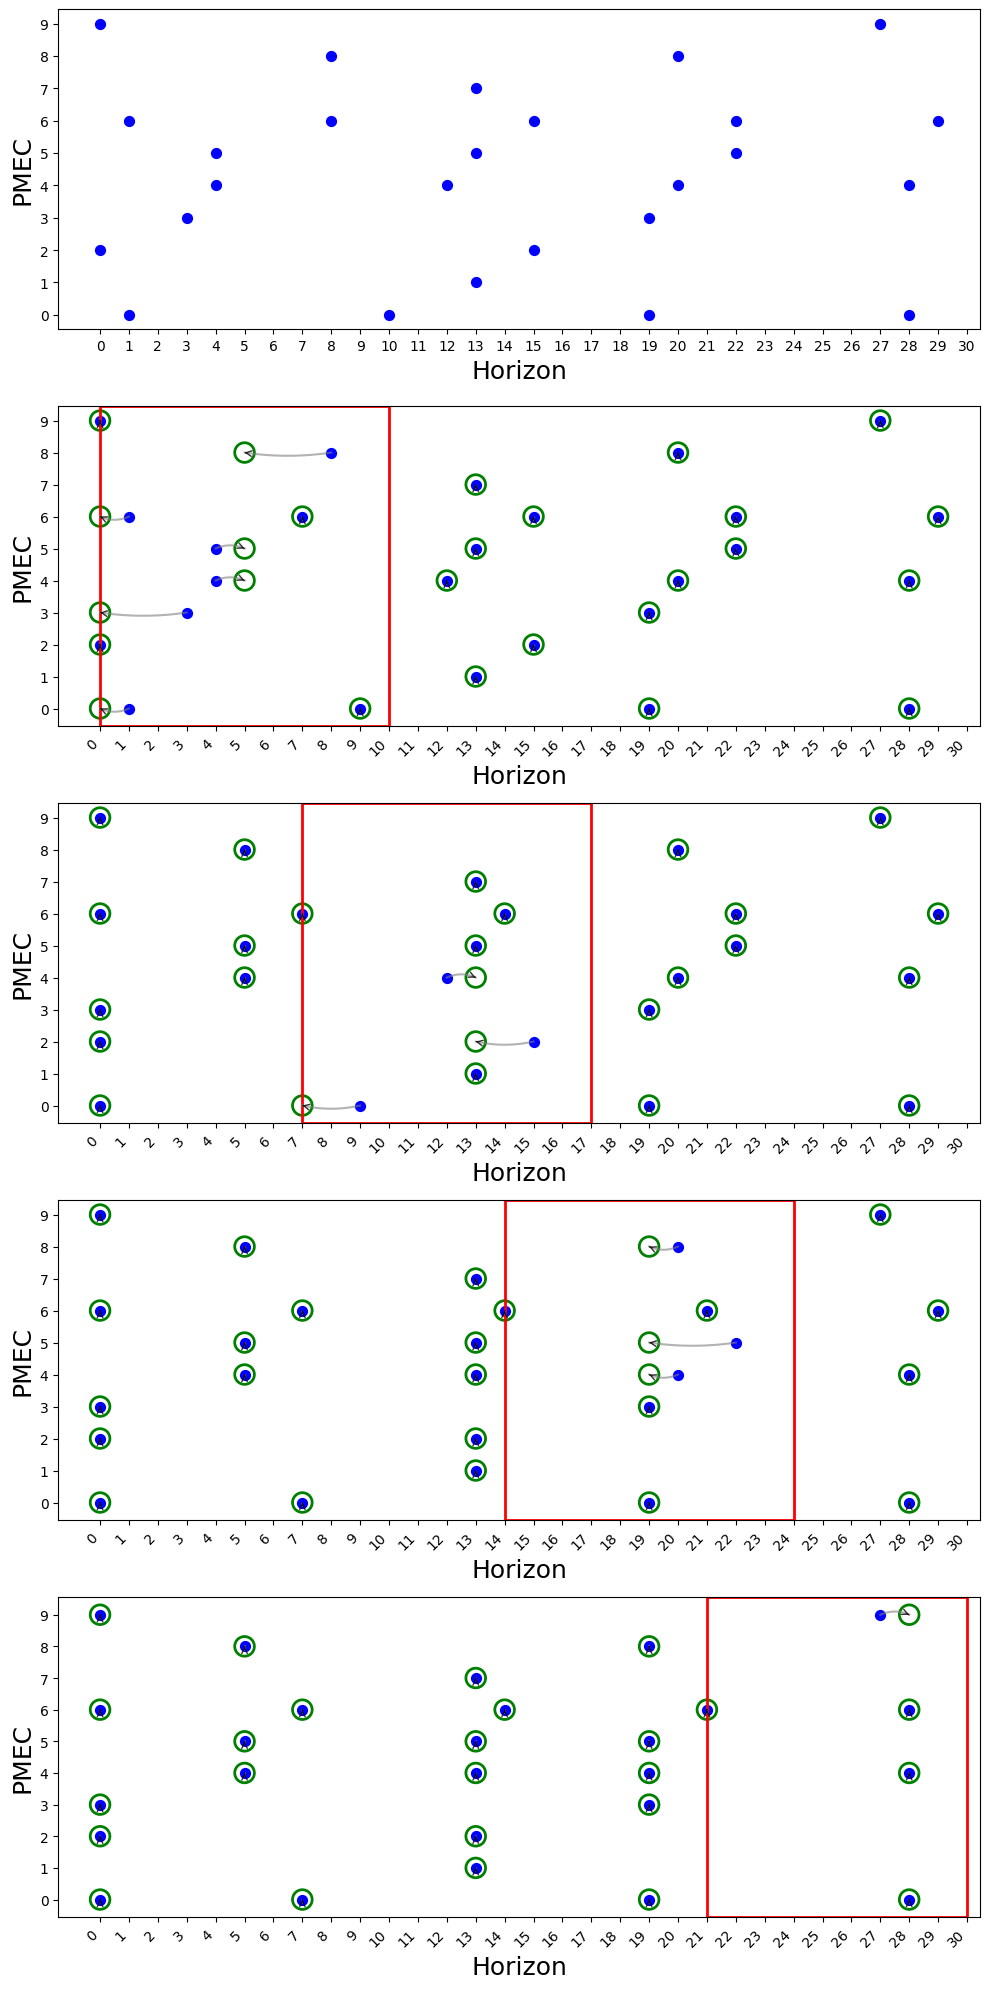

In [3]:
import matplotlib.pyplot as plt

def plot_all_dfs(df_history_list):
    n = len(df_history_list)  # calculate the number of tasks
    fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(10, 4 * n), sharex=True)
    
    if n == 1:
        axes = [axes]  # make axes iterable if there's only one subplot
    for i, df in enumerate(df_history_list):
        ax = axes[i]
        df_x = df[df['OPERATION'] == 'x'] # if we just draw x   replace df with df_x
        if i==0:
            ax.scatter(df_x['DATE'], df_x['CSEM'], color='blue', marker='o', label='DATE', s=50)
            ax.set_ylabel('PMEC')
            # ax.set_title('Sliding window grouping results')
            # ax.legend()
            axes[i].set_xlabel('Horizon', fontsize=18)  # 每一个子图设置 x 轴标签
            axes[i].set_ylabel('PMEC', fontsize=18)  # 每一个子图设置 y 轴标签
            y_ticks = np.arange(0, PARAMS['P'], 1) # axe x ticks from 0 to T
            ax.set_yticks(y_ticks)
            ax.tick_params(labelbottom=True)
            continue
    
        
        # plot the data points
        # colors = ['orange' if op == 'y' else 'blue' for op in df['OPERATION']] # if we draw x and y 
        # ax.scatter(df['DATE'], df['CSEM'], color='blue', marker='o', label='DATE', s=20)
        # ax.scatter(df['CENTER'], df['CSEM'], edgecolors='green', facecolors='none', marker='o', label='CENTER', s=100, linewidths=2)
        

        df_x = df[df['OPERATION'] == 'x'] # if we just draw x   replace df with df_x
        ax.scatter(df_x['DATE'], df_x['CSEM'], color='blue', marker='o', label='DATE', s=50)
        ax.scatter(df_x['CENTER'], df_x['CSEM'], edgecolors='green', facecolors='none', marker='o', label='CENTER', s=200, linewidths=2)
        
        # add the flowing arrows
        for j in range(len(df_x)):
            # x_start, y_start = df['DATE'][j], df['CSEM'][j]  # if we draw x and y
            # x_end, y_end = df['CENTER'][j], df['CSEM'][j]
 
            x_start, y_start = df_x['DATE'].iloc[j], df_x['CSEM'].iloc[j] ## if we just draw x
            x_end, y_end = df_x['CENTER'].iloc[j], df_x['CSEM'].iloc[j]
            
            # calculate the mid point for the curve
            mid_x = (x_start + x_end) / 2
            mid_y = y_start + (0.2 if x_end > x_start else -0.2)  # rise or fall the curve
            
            # create a quadratic Bezier curve
            t = np.linspace(0, 1, 100)
            curve_x = (1 - t) ** 2 * x_start + 2 * (1 - t) * t * mid_x + t ** 2 * x_end
            curve_y = (1 - t) ** 2 * y_start + 2 * (1 - t) * t * mid_y + t ** 2 * y_end
            
            ax.plot(curve_x, curve_y, color='gray', alpha=0.6)
            ax.annotate('', xy=(curve_x[-1], curve_y[-1]), xytext=(curve_x[-2], curve_y[-2]),
                        arrowprops=dict(arrowstyle='->', color='black', alpha=0.8))
        # add windows
        start = sliding_windows_starts[i-1]
        end = sliding_windows_ends[i-1]

        ax.add_patch(plt.Rectangle((start, ax.get_ylim()[0]), end-start, ax.get_ylim()[1]-ax.get_ylim()[0],
                                      edgecolor='red', facecolor='none', linewidth=2))
        
        x_min, x_max = int(df_x['DATE'].min()), int(df_x['DATE'].max())  
        # x_ticks = np.arange(x_min, x_max + 1, 1)  
        x_ticks = np.arange(0, PARAMS['T'] + 1, 1) # axe x ticks from 0 to T
        ax.set_xticks(x_ticks)
        y_ticks = np.arange(0, PARAMS['P'], 1) # axe x ticks from 0 to T
        ax.set_yticks(y_ticks)
        ax.set_xticklabels(x_ticks, rotation=45, ha="right")  # 旋转刻度值，避免重叠
        axes[i].set_xlabel('Horizon', fontsize=18)  # 每一个子图设置 x 轴标签
        axes[i].set_ylabel('PMEC', fontsize=18)  # 每一个子图设置 y 轴标签
        ax.tick_params(labelbottom=True) # 显示 x 轴刻度值
        
    # axes[-1].set_xlabel('Time Units')  # 只在最后一个子图设置 x 轴标签
    plt.tight_layout()
    plt.show()

# plot the results
plot_all_dfs(df_history_list)


In [4]:
df_history_list[3]

,INDEX,CSEM,INITIALP,OPERATION,DATE,CENTER
0,0,0,3.27,x,0,0
1,1,0,3.27,x,7,7
2,2,0,3.27,x,19,19
3,3,0,3.27,x,28,28
4,4,1,3.35,x,13,13
5,5,2,3.21,x,0,0
6,6,2,3.21,x,13,13
7,7,3,3.26,x,0,0
8,8,3,3.26,x,19,19
9,9,4,3.39,x,5,5


Cost before grouping: 2600
Cost after grouping: 790
 CS cost after grouping: 800
 Total penalty after grouping: 10
Gas leakage before clustering: 44.364
Gas leakage after clustering: 45.718


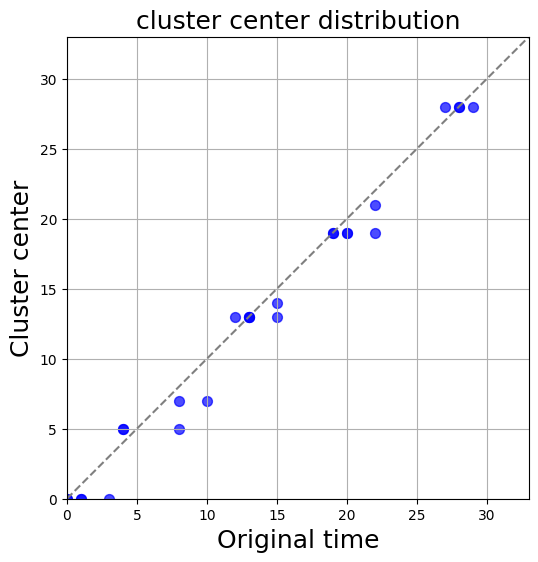

Center counts: CENTER
0     5
19    5
13    5
28    4
5     3
7     2
14    1
21    1
Name: count, dtype: int64
Results:
    INDEX  CSEM  INITIALP OPERATION  DATE  CENTER
0       0     0      3.27         x     0       0
1       1     0      3.27         x     7       7
2       2     0      3.27         x    19      19
3       3     0      3.27         x    28      28
4       4     1      3.35         x    13      13
5       5     2      3.21         x     0       0
6       6     2      3.21         x    13      13
7       7     3      3.26         x     0       0
8       8     3      3.26         x    19      19
9       9     4      3.39         x     5       5
10     10     4      3.39         x    13      13
11     11     4      3.39         x    19      19
12     12     4      3.39         x    28      28
13     13     5      3.36         x     5       5
14     14     5      3.36         x    13      13
15     15     5      3.36         x    19      19
16     16     6      3.27    

In [ ]:

# calculate the cost before grouping
operation_x_count = (result_df['OPERATION'] == 'x').sum()
# operation_y_count = (result_df['OPERATION'] == 'y').sum()
# before_cost = operation_x_count * 10 + operation_y_count * 100
before_cost = operation_x_count * 100 

print(f"Cost before grouping: {before_cost}")

# calculate the cost after grouping
operation_x_center_unique_count = result_df[result_df['OPERATION'] == 'x']['CENTER'].nunique()
total_penalty = np.sum(
    np.where(
        result_df['CENTER'] - result_df['DATE'] < 0,
        abs(result_df['CENTER'] - result_df['DATE']) * PARAMS['alpha'],
        abs(result_df['CENTER'] - result_df['DATE']) * PARAMS['beta']
    )
)
# operation_y_count = (result_df['OPERATION'] == 'y').sum()
# after_cost = operation_x_center_unique_count * 10 + operation_y_count * 100
CS_COST = operation_x_center_unique_count * 100
after_cost = CS_COST - total_penalty

print(f"Cost after grouping: {after_cost}")
print(f" CS cost after grouping: {CS_COST}")
print(f" Total penalty after grouping: {total_penalty}")

# calculate the gas leakage before clustering
df = pd.read_csv('maintenance_plan.csv')
leakage_before = round(calculate_gas_leakage_before(df, PARAMS['T']), 3)

print(f"Gas leakage before clustering: {leakage_before}")

# calculate the gas leakage after clustering
leakage_after = round(calculate_gas_leakage_after(result_df, PARAMS['T']), 3)
print(f"Gas leakage after clustering: {leakage_after}")


# Plot1: cluster center vs original time
plt.figure(figsize=(6, 6))
# set colors：if OPERATION == "y"，red else blue   # if we draw x and y previous version
# colors = ['orange' if op == 'y' else 'blue' for op in result_df['OPERATION']]

df = df[df['OPERATION'] == 'x']  # if we just draw x
result_df = result_df[result_df['OPERATION'] == 'x']  # if we just draw x
plt.scatter(df['DATE'], result_df['CENTER'], color = 'blue', alpha=0.7, s=50)

# title and labels
plt.title("cluster center distribution", fontsize=18)
plt.xlabel("Original time", fontsize=18)
plt.ylabel("Cluster center", fontsize=18)
plt.grid(True)

# set x and y axis limits
max_range = max(result_df['DATE'].max(), result_df['CENTER'].max()+5)
plt.xlim(0, max_range)
plt.ylim(0, max_range)

# add diagonal line
plt.plot([0, max_range], [0, max_range], color='gray', linestyle='--', label='45° diagonal')
# set aspect ratio to be equal
plt.gca().set_aspect('equal')
plt.show()

center_counts = result_df['CENTER'].value_counts()
print("Center counts:", center_counts)
print("Results:")
print(result_df)
result_df.to_csv('result.csv', index=False)
print("Result saved to result.csv")

In [131]:
# Gurobi version
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
from gurobipy import Model as GurobiModel, GRB
from gurobipy import quicksum



# define the parameters
PARAMS = {
    'P': 100,        # number of caissons
    'T': 360,      # horizon
    'Cmax':20,      # maximum number of tasks of one cluster
    'window_size': 10,   # window size
    'advanced': 3,          # advanced time
    'K': 5.993,         # leakage coefficient
    'alpha': 5,    # unit cost of advancing one day
    'beta': 10,       # unit cost of delaying one day
    'Cs':100      # Unit setup cost
}   

# initialize the random values
random.seed(42)
# alpha_values = [round(random.uniform(0.03, 0.08), 3) for _ in range(PARAMS['P'])]
alpha_values = [round(random.uniform(0.01, 0.05), 3) for _ in range(PARAMS['P'])]   # degradation rate for each caisson
initial_p_values = [round(random.uniform(3.2, 3.5), 2) for i in range(PARAMS['P'])]
print("alpha values:", alpha_values)

def calculate_maintenance_period_from_data(df, d_min_ratio=0.6, d_max_ratio=1.4):
    """extract maintenance periods from data"""
    
    maintenance_periods = {}
    D_min_dict = {}
    D_max_dict = {}
    
    print("\n===== 从数据中提取维修周期 =====")
    print(f"{'Caisson':<10} {'间隔数':<10} {'间隔范围':<20} {'周期':<12} {'D_min':<10} {'D_max':<10}")
    print("-" * 80)
    
    for caisson_id in sorted(df['CSEM'].unique()):
        # 步骤1：筛选该caisson的所有'x'操作
        caisson_tasks = df[
            (df['CSEM'] == caisson_id) & 
            (df['OPERATION'] == 'x')
        ].sort_values('DATE')
        
        # Step 2: Check if there are at least 2 tasks
        if len(caisson_tasks) < 2:
            default_period = PARAMS['window_size']  # ← 新增
            maintenance_periods[caisson_id] = default_period
            D_min_dict[caisson_id] = int(np.ceil(default_period * d_min_ratio))
            D_max_dict[caisson_id] = int(np.ceil(default_period * d_max_ratio))
            print(f"... {default_period:<12.2f} ...")  
            continue
        
        # 步骤3：计算相邻任务之间的间隔
        intervals = []
        for i in range(1, len(caisson_tasks)):
            interval = caisson_tasks.iloc[i]['DATE'] - caisson_tasks.iloc[i-1]['DATE']
            intervals.append(interval)
        
        # 步骤4：使用中位数作为维修周期
        maintenance_period = np.mean(intervals)
        maintenance_periods[caisson_id] = maintenance_period
        
        # 步骤5：计算D_min和D_max
        D_min_dict[caisson_id] = int(np.ceil(maintenance_period * d_min_ratio))
        D_max_dict[caisson_id] = int(np.ceil(maintenance_period * d_max_ratio))
        
        # 步骤6：打印结果
        interval_min = min(intervals)
        interval_max = max(intervals)
        interval_range = f"[{interval_min}, {interval_max}]"
        
        print(f"{caisson_id:<10} {len(intervals):<10} {interval_range:<20} "
              f"{maintenance_period:<12.2f} {D_min_dict[caisson_id]:<10} {D_max_dict[caisson_id]:<10}")
    
    print("===== 提取完成 =====\n")
    
    return maintenance_periods, D_min_dict, D_max_dict


def clustering_CR(df_window, window_size, window_start, global_task_count, full_df, D_min_dict, D_max_dict):
    """Grouping model implemented with Gurobi. Function signature and variable names
    are kept identical to the original docplex version so it can be drop-in replaced.
    """

    # add preprocessing here
    if df_window.empty or window_size < 1:
        print(f"warning: window {window_start} has no tasks or window size is invalid")
        return df_window  # return the original dataframe if no tasks in the window

    N = df_window.shape[0]  # number of tasks in the window

    mdl = GurobiModel('Dynamic_Window_Clustering')
    mdl.setParam('OutputFlag', 0)  # turn off solver output by default

    # define the variables
    data_pos_num = window_size + 1
    # theta[n,t]
    theta = mdl.addVars(N, data_pos_num, vtype=GRB.BINARY, name='theta')
    # CS[t]
    CS = mdl.addVars(data_pos_num, lb=0.0, vtype=GRB.CONTINUOUS, name='CS')
    # y[t]
    y = mdl.addVars(data_pos_num, vtype=GRB.BINARY, name='y')

    # convenience: access as theta[n, t]

    a = [0] * N
    b = [0] * N

    # every task must be assigned to one cluster
    for n in range(N):
        mdl.addConstr(theta.sum(n, '*') == 1, name=f"assign_task_{n}")

    # maximum capacity in each cluster
    for t in range(data_pos_num):
        mdl.addConstr(theta.sum('*', t) <= PARAMS['Cmax'], name=f"cap_{t}")

    # define the possible advanced or delayed range for each task: local time
    for n in range(N):
        local_time = int(df_window.iloc[n]['window_time'])
        a[n] = int(max(0, local_time - PARAMS['advanced']))
        b[n] = int(min(data_pos_num, local_time + int((3.2 - 3.0)/alpha_values[int(df_window.iloc[n]["CSEM"])]) - 2))

    # cluster center constraints
    for n in range(N):
        for t in range(data_pos_num):
            # t * theta[n,t] + a[n] * (1 - theta[n,t]) >= a[n]
            # equivalently: (t - a[n]) * theta[n,t] >= 0  when rearranged, but keep original form for clarity
            mdl.addConstr(t * theta[n, t] + a[n] * (1 - theta[n, t]) >= a[n], name=f"lb_range_n{n}_t{t}")
            mdl.addConstr(t * theta[n, t] + b[n] * (1 - theta[n, t]) <= b[n], name=f"ub_range_n{n}_t{t}")

    # ensure y[t] indicates whether cluster t is used
    M = PARAMS['Cmax']
    for t in range(data_pos_num):
        task_count = theta.sum('*', t)
        # task_count >= 1 - M*(1 - y[t])  <=> task_count + M*(1-y[t]) >= 1
        mdl.addConstr(task_count + M * (1 - y[t]) >= 1, name=f"activate_lb_{t}")
        # task_count <= M * y[t]
        mdl.addConstr(task_count <= M * y[t], name=f"activate_ub_{t}")

    # setup cost (same expression as original)
    setup_cost = PARAMS['Cs'] * (theta.sum() - y.sum())

    # build cost matrix and CP_total
    cost_matrix = {}
    for n in range(N):
        local_time_n = int(df_window.iloc[n]['window_time'])
        for t in range(data_pos_num):
            deviation = t - local_time_n
            if deviation > 0:
                cost_matrix[(n, t)] = PARAMS['beta'] * deviation
            elif deviation < 0:
                cost_matrix[(n, t)] = PARAMS['alpha'] * (-deviation)
            else:
                cost_matrix[(n, t)] = 0

    # total cost (linear expression)
    CP_total = quicksum(cost_matrix[(n, t)] * theta[n, t] for n in range(N) for t in range(data_pos_num))

    # maintenance constraints (skip for first window)
    for n in range(N):
        row = df_window.iloc[n]
        caisson = int(row['CSEM'])

        if window_start == 0:
            print(f"  Caisson {caisson}: skip constraint (first window)")
            continue

        prev_rows = full_df[
            (full_df['CSEM'] == caisson) &
            (full_df['CENTER'] < row['DATE']) &
            (full_df['OPERATION'] == 'x')
        ].sort_values('CENTER')

        if prev_rows.empty:
            prev_center = 0
            print(f"  Caisson {caisson}: first task ever, prev_center=0")
            continue

        prev_center = int(prev_rows.iloc[-1]['CENTER'])
        print(f"  Caisson {caisson}: prev_center={prev_center}")

        # t_now_local = sum(t * theta[n,t])
        t_now_local = quicksum(t * theta[n, t] for t in range(data_pos_num))
        # t_now_global = t_now_local + window_start
        # Add maintenance distance constraints: d_min <= t_now_global - prev_center <= d_max
        d_min_i = D_min_dict[caisson]
        d_max_i = D_max_dict[caisson]

        mdl.addConstr(t_now_local + window_start - prev_center >= d_min_i, name=f"dmin_n{n}")
        mdl.addConstr(t_now_local + window_start - prev_center <= d_max_i, name=f"dmax_n{n}")

    # objective
    obj = setup_cost - CP_total
    mdl.setObjective(obj, GRB.MAXIMIZE)

    # optimize
    mdl.optimize()

    if mdl.status != GRB.OPTIMAL and mdl.status != GRB.TIME_LIMIT and mdl.status != GRB.SUBOPTIMAL:
        print(f"Failed to solve the problem: status {mdl.status}")
        return None

    # result processing
    centers = {}
    for n in range(N):
        for t in range(data_pos_num):
            val = theta[n, t].X
            if val is not None and round(val) == 1:
                centers[n] = t + window_start
                break

    index_n_list = df_window.INDEX.tolist()

    for n in range(len(index_n_list)):
        for t in range(data_pos_num):
            if round(theta[n, t].X) == 1:
                df_window.loc[df_window['INDEX'] == index_n_list[n], 'CENTER'] = centers.get(n, 0)

    # model stats (similar info to docplex prints)
    print(f"Model stats: {mdl.NumVars} vars, {mdl.NumConstrs} cons")
    print(f"Objective value: {mdl.ObjVal if hasattr(mdl, 'ObjVal') else mdl.getObjective().getValue()}")

    return df_window


def calculate_gas_leakage_before(df, T):
    total_leakage = 0

    for csem in df['CSEM'].unique():
        # filter the data for the current CSEM
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x']
        y_operations = csem_data[csem_data['OPERATION'] == 'y']
        alpha = alpha_values[csem]

        # deal with the 'x' operations in the middle
        for i in range(1, len(x_operations)):
            current_x = x_operations.iloc[i]
            previous_x = x_operations.iloc[i - 1]
            center_diff = current_x['DATE'] - previous_x['DATE'] - 1
            total_leakage += center_diff * alpha * PARAMS['K']

        # deal with the first 'x' operation
        if not x_operations.empty:
            first_x = x_operations.iloc[0]
            total_leakage += first_x['DATE'] * alpha * PARAMS['K']

        # deal with the last 'x' operation (special handling)
        last_x = x_operations.iloc[-1]
        last_x_end = last_x['DATE'] + 1  # end of last maintenance day
        
        if not y_operations.empty:
            # if there is a 'y' operation
            y_center = y_operations['DATE'].iloc[0]
            leak_time = max(0, y_center - last_x_end)
            total_leakage += leak_time * alpha * PARAMS['K']
        else:
            # if there is no 'y' operation
            leak_time = max(0, T - last_x_end)
            total_leakage += leak_time * alpha * PARAMS['K']

    return total_leakage


# function to calculate the gas leakage after clustering
def calculate_gas_leakage_after(df, T):
    total_leakage = 0

    for csem in df['CSEM'].unique():
        # filter the data for the current CSEM
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x']
        y_operations = csem_data[csem_data['OPERATION'] == 'y']
        alpha = alpha_values[csem]

        # deal with the 'x' operations in the middle
        for i in range(1, len(x_operations)):
            current_x = x_operations.iloc[i]
            previous_x = x_operations.iloc[i - 1]
            center_diff = current_x['CENTER'] - previous_x['CENTER'] - 1
            total_leakage += center_diff * alpha * PARAMS['K']

        # deal with the first 'x' operation
        if not x_operations.empty:
            first_x = x_operations.iloc[0]
            total_leakage += first_x['CENTER'] * alpha * PARAMS['K']

    
        # deal with the last 'x' operation (special handling)
        last_x = x_operations.iloc[-1]
        last_x_end = last_x['CENTER'] + 1  # end of last maintenance day
        
        if not y_operations.empty:
            # if there is a 'y' operation
            y_center = y_operations['DATE'].iloc[0]
            leak_time = max(0, y_center - last_x_end)
            total_leakage += leak_time * alpha * PARAMS['K']
        else:
            # if there is no 'y' operation
            leak_time = max(0, T - last_x_end)
            total_leakage += leak_time * alpha * PARAMS['K']

    return total_leakage

def main(window_size):
    """Main function"""
    
    df = pd.read_csv('maintenance_plan.csv')
    df_init = df.copy()
    df_history_list = []
    df_history_list.append(df_init)
    sliding_windows_starts = []
    sliding_windows_ends = []
    # df['CENTER'] = 0  # initialize the center column
    df['CENTER'] = df['DATE']  # initialize the center column

    # 新增这7行
    maintenance_periods, D_min_dict, D_max_dict = calculate_maintenance_period_from_data(df=df, d_min_ratio=0.5, d_max_ratio=1.5)
    PARAMS['D_min'] = D_min_dict
    PARAMS['D_max'] = D_max_dict


    # 全局变量：记录每一天的任务数量
    global_task_count = [0] * PARAMS['T'] * 2
    window_start = 0

    while window_start <= PARAMS['T']:
        # dynamic window selection
        window_end = window_start + window_size
        if window_end > PARAMS['T']:
            window_end = PARAMS['T']
        
        sliding_windows_starts.append(window_start)
        sliding_windows_ends.append(window_end)
        mask = (df['DATE'] >= window_start) & (df['DATE'] <= window_end) & (df['OPERATION']== 'x')  

        window_df = df.loc[mask].copy()

        # task local time conversion
        window_df['window_time'] = window_df['DATE'] - window_start

        first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])

        # clustering these first tasks in the window
        clustered_df = clustering_CR(first_tasks, window_size, window_start, global_task_count, df, D_min_dict, D_max_dict)
        
        if clustered_df is not None:
            # update the center column of original dataframe
            center_map = clustered_df.set_index('INDEX')['CENTER']

            df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)

            # update the secondary tasks time
            update_secondary_tasks(df, clustered_df, window_start, window_end)


        # slide the window to the next task that haven't been clustered yet   !!! new version
        second_dates = []
        for caisson in clustered_df["CSEM"].unique():
            # 获取该 caisson 在当前窗口内的任务
            tasks = df[
                (df['CSEM'] == caisson) & 
                (df['OPERATION'] == 'x') &
                (df['DATE'].between(window_start, window_end))
            ].sort_values('DATE')

            # 如果有至少两个任务，取第二个的 DATE
            if len(tasks) > 1:
                second_date = tasks.iloc[1]['DATE']
                second_dates.append(second_date)

        # 如果有至少一个有效的 second_date，就更新窗口起点
        if second_dates:
            window_start = min(second_dates)
        else:
            # fallback：维持旧逻辑，或推进一整个窗口长度
            window_start = window_start + window_size  # 或者 clustered_df['CENTER'].max() + 1
        # ---------------

        df_history_list.append(df.copy())

        if window_end>=PARAMS['T']:
            break

        df.loc[df['INDEX'].isin(center_map.index), 'DATE'] = df['INDEX'].map(center_map)
    # Updates the center column of the RE operation, which will not be grouped
    df.loc[df['OPERATION'] == "y", 'CENTER'] = df.loc[df['OPERATION'] == "y", 'DATE']

    # Processing of the remaining tasks that are not assigned to a center and cannot be updated
    mask_remain = (df['OPERATION'] == "x") & (df['CENTER'] == 0)
    df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']


        # ====== 新增：检查最终任务间隔（诊断用）======
    df_sorted = df[df['OPERATION']=='x'].sort_values(['CSEM', 'CENTER'])
    df_sorted['PREV_CENTER'] = df_sorted.groupby('CSEM')['CENTER'].shift(1)
    df_sorted['GAP'] = df_sorted['CENTER'] - df_sorted['PREV_CENTER']
    print("\n===== 最终任务间隔分析 =====")
    print(df_sorted[['CSEM','CENTER','PREV_CENTER','GAP']].head(20))
    print(f"gap min: {df_sorted['GAP'].min()}, gap max: {df_sorted['GAP'].max()}")
    print("===== 分析结束 =====\n")
    # ====== 诊断代码结束 ======
    
    
    # result verification
    # assert df['CENTER'].notna().all(), "Some tasks are not clustered"
    return df, df_history_list, sliding_windows_starts, sliding_windows_ends

# function to update the secondary tasks date of each window
def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
    """Update the secondary tasks time"""
    for caisson in clustered_df["CSEM"].unique():
        # get the tasks in the same caisson
        tasks = main_df[
            (main_df['CSEM'] == caisson) & 
            (main_df['DATE'].between(window_start, window_end)) 
        ]
        tasks = main_df[
            (main_df['CSEM'] == caisson) & 
            (main_df['DATE'].between(window_start, window_end)) & 
            (main_df['OPERATION'] == 'x')
        ]
        
        if len(tasks) > 1:
            # get the second task index
            second_idx = tasks.index[1]
            
            # get the previous center time amd calculate the new time for the second task
            center_time = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
            
            # calulate the new time
            alpha = alpha_values[caisson]
            new_date = int(center_time + 1 + (3.5-3.2)/alpha)
            
            # update the time
            main_df.loc[second_idx, ['DATE', 'CENTER']] = new_date, new_date





alpha values: [0.036, 0.011, 0.021, 0.019, 0.039, 0.037, 0.046, 0.013, 0.027, 0.011, 0.019, 0.03, 0.011, 0.018, 0.036, 0.032, 0.019, 0.034, 0.042, 0.01, 0.042, 0.038, 0.024, 0.016, 0.048, 0.023, 0.014, 0.014, 0.044, 0.034, 0.042, 0.039, 0.031, 0.049, 0.025, 0.032, 0.043, 0.035, 0.044, 0.033, 0.038, 0.012, 0.019, 0.022, 0.013, 0.019, 0.014, 0.021, 0.035, 0.025, 0.025, 0.018, 0.021, 0.047, 0.036, 0.034, 0.017, 0.039, 0.017, 0.025, 0.05, 0.036, 0.032, 0.037, 0.044, 0.041, 0.019, 0.011, 0.023, 0.021, 0.018, 0.048, 0.045, 0.023, 0.036, 0.026, 0.047, 0.028, 0.021, 0.02, 0.032, 0.021, 0.033, 0.046, 0.026, 0.019, 0.05, 0.03, 0.014, 0.012, 0.014, 0.035, 0.042, 0.027, 0.013, 0.025, 0.05, 0.031, 0.049, 0.044]


In [132]:
result_df, df_history_list, sliding_windows_starts, sliding_windows_ends = main(PARAMS['window_size'])


===== 从数据中提取维修周期 =====
Caisson    间隔数        间隔范围                 周期           D_min      D_max     
--------------------------------------------------------------------------------
0          5          [9, 9]               9.00         5          14        
1          5          [28, 28]             28.00        14         42        
2          7          [15, 15]             15.00        8          23        
3          6          [16, 16]             16.00        8          24        
4          6          [8, 8]               8.00         4          12        
5          6          [9, 9]               9.00         5          14        
6          5          [7, 7]               7.00         4          11        
7          9          [23, 23]             23.00        12         35        
8          5          [12, 12]             12.00        6          18        
9          9          [27, 27]             27.00        14         41        
10         8          [17, 17]       

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_15314/3233614518.py:348: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_15314/3233614518.py:348: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

  Caisson 0: prev_center=9
  Caisson 1: first task ever, prev_center=0
  Caisson 2: prev_center=9
  Caisson 3: prev_center=9
  Caisson 4: prev_center=9
  Caisson 5: prev_center=5
  Caisson 6: prev_center=8
  Caisson 8: prev_center=5
  Caisson 10: first task ever, prev_center=0
  Caisson 11: prev_center=12
  Caisson 13: prev_center=2
  Caisson 14: prev_center=5
  Caisson 15: prev_center=9
  Caisson 16: prev_center=4
  Caisson 17: prev_center=5
  Caisson 18: prev_center=12
  Caisson 20: prev_center=12
  Caisson 21: prev_center=12
  Caisson 22: prev_center=9
  Caisson 24: prev_center=8
  Caisson 25: prev_center=4
  Caisson 26: prev_center=0
  Caisson 27: first task ever, prev_center=0
  Caisson 28: prev_center=12
  Caisson 29: prev_center=5
  Caisson 30: prev_center=8
  Caisson 31: prev_center=8
  Caisson 32: prev_center=9
  Caisson 33: prev_center=12
  Caisson 35: prev_center=4
  Caisson 36: prev_center=8
  Caisson 37: prev_center=5
  Caisson 38: prev_center=12
  Caisson 39: prev_center=

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_15314/3233614518.py:348: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_15314/3233614518.py:348: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

  Caisson 0: prev_center=17
  Caisson 4: prev_center=17
  Caisson 5: prev_center=23
  Caisson 6: prev_center=22
  Caisson 7: prev_center=9
  Caisson 8: prev_center=17
  Caisson 10: prev_center=14
  Caisson 11: prev_center=22
  Caisson 13: prev_center=19
  Caisson 14: prev_center=23
  Caisson 15: prev_center=17
  Caisson 16: prev_center=20
  Caisson 17: prev_center=23
  Caisson 18: prev_center=20
  Caisson 19: prev_center=4
  Caisson 20: prev_center=20
  Caisson 21: prev_center=20
  Caisson 22: prev_center=22
  Caisson 23: prev_center=9
  Caisson 24: prev_center=22
  Caisson 25: prev_center=17
  Caisson 28: prev_center=19
  Caisson 29: prev_center=23
  Caisson 30: prev_center=17
  Caisson 31: prev_center=23
  Caisson 32: prev_center=17
  Caisson 33: prev_center=19
  Caisson 35: prev_center=23
  Caisson 36: prev_center=22
  Caisson 37: prev_center=23
  Caisson 38: prev_center=19
  Caisson 39: prev_center=20
  Caisson 40: prev_center=19
  Caisson 42: prev_center=20
  Caisson 43: prev_cent

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_15314/3233614518.py:348: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_15314/3233614518.py:348: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

... (2 outputs left out)

  Caisson 2: prev_center=55
  Caisson 3: prev_center=55
  Caisson 8: prev_center=52
  Caisson 10: prev_center=48
  Caisson 12: prev_center=41
  Caisson 13: prev_center=52
  Caisson 15: prev_center=58
  Caisson 16: prev_center=52
  Caisson 17: prev_center=58
  Caisson 19: prev_center=34
  Caisson 21: prev_center=61
  Caisson 23: prev_center=47
  Caisson 25: prev_center=55
  Caisson 26: prev_center=44
  Caisson 27: prev_center=41
  Caisson 29: prev_center=61
  Caisson 32: prev_center=58
  Caisson 37: prev_center=61
  Caisson 39: prev_center=61
  Caisson 41: prev_center=38
  Caisson 42: prev_center=52
  Caisson 43: prev_center=55
  Caisson 45: prev_center=51
  Caisson 47: prev_center=55
  Caisson 49: prev_center=55
  Caisson 50: prev_center=51
  Caisson 52: prev_center=51
  Caisson 53: prev_center=58
  Caisson 62: prev_center=61
  Caisson 63: prev_center=61
  Caisson 64: prev_center=55
  Caisson 66: prev_center=51
  Caisson 67: prev_center=44
  Caisson 68: prev_center=58
  Caisson 70: pre

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_15314/3233614518.py:348: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_15314/3233614518.py:348: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

  Caisson 2: prev_center=99
  Caisson 10: prev_center=99
  Caisson 16: prev_center=99
  Caisson 22: prev_center=99
  Caisson 25: prev_center=109
  Caisson 41: prev_center=91
  Caisson 42: prev_center=99
  Caisson 45: prev_center=99
  Caisson 46: prev_center=99
  Caisson 47: prev_center=99
  Caisson 49: prev_center=104
  Caisson 58: prev_center=99
  Caisson 70: prev_center=99
  Caisson 79: prev_center=104
  Caisson 88: prev_center=94
  Caisson 89: prev_center=86
  Caisson 90: prev_center=94
Model stats: 209 vars, 458 cons
Objective value: 1390.0
  Caisson 1: prev_center=104
  Caisson 7: prev_center=99
  Caisson 10: prev_center=114
  Caisson 12: prev_center=94
  Caisson 16: prev_center=114
  Caisson 19: prev_center=94
  Caisson 23: prev_center=104
  Caisson 26: prev_center=109
  Caisson 27: prev_center=109
  Caisson 44: prev_center=99
  Caisson 45: prev_center=114
  Caisson 47: prev_center=114
  Caisson 51: prev_center=109
  Caisson 67: prev_center=99
  Caisson 78: prev_center=109
  Cais

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_15314/3233614518.py:348: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_15314/3233614518.py:348: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

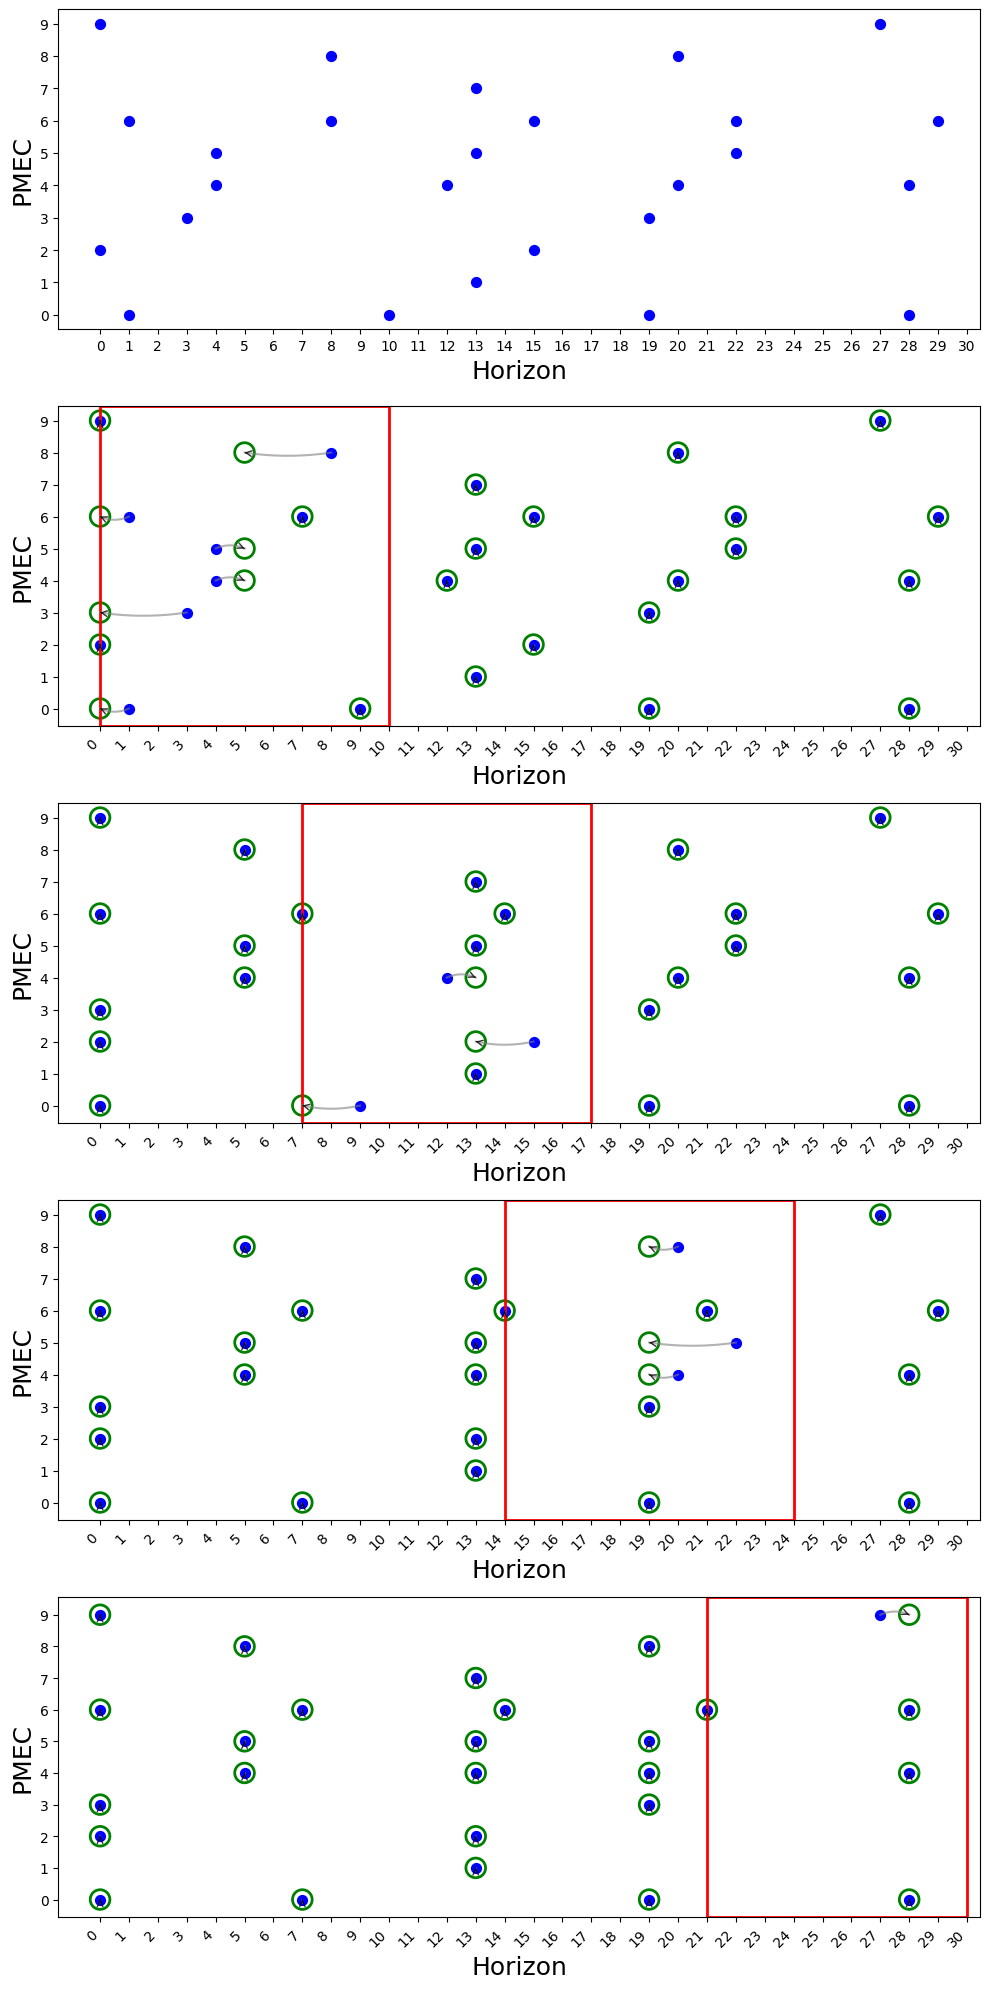

In [5]:
import matplotlib.pyplot as plt

def plot_all_dfs(df_history_list):
    n = len(df_history_list)  # calculate the number of tasks
    fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(10, 4 * n), sharex=True)
    
    if n == 1:
        axes = [axes]  # make axes iterable if there's only one subplot
    for i, df in enumerate(df_history_list):
        ax = axes[i]
        df_x = df[df['OPERATION'] == 'x'] # if we just draw x   replace df with df_x
        if i==0:
            ax.scatter(df_x['DATE'], df_x['CSEM'], color='blue', marker='o', label='DATE', s=50)
            ax.set_ylabel('PMEC')
            # ax.set_title('Sliding window grouping results')
            # ax.legend()
            axes[i].set_xlabel('Horizon', fontsize=18)  # 每一个子图设置 x 轴标签
            axes[i].set_ylabel('PMEC', fontsize=18)  # 每一个子图设置 y 轴标签
            y_ticks = np.arange(0, PARAMS['P'], 1) # axe x ticks from 0 to T
            ax.set_yticks(y_ticks)
            ax.tick_params(labelbottom=True)
            continue
    
        
        # plot the data points
        # colors = ['orange' if op == 'y' else 'blue' for op in df['OPERATION']] # if we draw x and y 
        # ax.scatter(df['DATE'], df['CSEM'], color='blue', marker='o', label='DATE', s=20)
        # ax.scatter(df['CENTER'], df['CSEM'], edgecolors='green', facecolors='none', marker='o', label='CENTER', s=100, linewidths=2)
        

        df_x = df[df['OPERATION'] == 'x'] # if we just draw x   replace df with df_x
        ax.scatter(df_x['DATE'], df_x['CSEM'], color='blue', marker='o', label='DATE', s=50)
        ax.scatter(df_x['CENTER'], df_x['CSEM'], edgecolors='green', facecolors='none', marker='o', label='CENTER', s=200, linewidths=2)
        
        # add the flowing arrows
        for j in range(len(df_x)):
            # x_start, y_start = df['DATE'][j], df['CSEM'][j]  # if we draw x and y
            # x_end, y_end = df['CENTER'][j], df['CSEM'][j]
 
            x_start, y_start = df_x['DATE'].iloc[j], df_x['CSEM'].iloc[j] ## if we just draw x
            x_end, y_end = df_x['CENTER'].iloc[j], df_x['CSEM'].iloc[j]
            
            # calculate the mid point for the curve
            mid_x = (x_start + x_end) / 2
            mid_y = y_start + (0.2 if x_end > x_start else -0.2)  # rise or fall the curve
            
            # create a quadratic Bezier curve
            t = np.linspace(0, 1, 100)
            curve_x = (1 - t) ** 2 * x_start + 2 * (1 - t) * t * mid_x + t ** 2 * x_end
            curve_y = (1 - t) ** 2 * y_start + 2 * (1 - t) * t * mid_y + t ** 2 * y_end
            
            ax.plot(curve_x, curve_y, color='gray', alpha=0.6)
            ax.annotate('', xy=(curve_x[-1], curve_y[-1]), xytext=(curve_x[-2], curve_y[-2]),
                        arrowprops=dict(arrowstyle='->', color='black', alpha=0.8))
        # add windows
        start = sliding_windows_starts[i-1]
        end = sliding_windows_ends[i-1]

        ax.add_patch(plt.Rectangle((start, ax.get_ylim()[0]), end-start, ax.get_ylim()[1]-ax.get_ylim()[0],
                                      edgecolor='red', facecolor='none', linewidth=2))
        
        x_min, x_max = int(df_x['DATE'].min()), int(df_x['DATE'].max())  
        # x_ticks = np.arange(x_min, x_max + 1, 1)  
        x_ticks = np.arange(0, PARAMS['T'] + 1, 1) # axe x ticks from 0 to T
        ax.set_xticks(x_ticks)
        y_ticks = np.arange(0, PARAMS['P'], 1) # axe x ticks from 0 to T
        ax.set_yticks(y_ticks)
        ax.set_xticklabels(x_ticks, rotation=45, ha="right")  # 旋转刻度值，避免重叠
        axes[i].set_xlabel('Horizon', fontsize=18)  # 每一个子图设置 x 轴标签
        axes[i].set_ylabel('PMEC', fontsize=18)  # 每一个子图设置 y 轴标签
        ax.tick_params(labelbottom=True) # 显示 x 轴刻度值
        
    # axes[-1].set_xlabel('Time Units')  # 只在最后一个子图设置 x 轴标签
    plt.tight_layout()
    plt.show()

# plot the results
plot_all_dfs(df_history_list)


Cost before grouping: 77700
Cost after grouping: 10045
 CS cost after grouping: 6600
 Total penalty after grouping: 3445
Gas leakage before clustering: 1412.598
Gas leakage after clustering: 1412.598


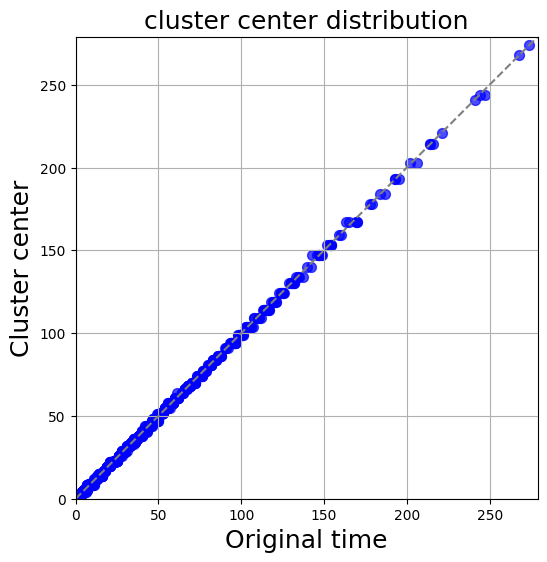

Center counts: CENTER
9      20
52     20
14     20
41     20
23     20
       ..
140     2
274     1
268     1
221     1
241     1
Name: count, Length: 66, dtype: int64
Results:
     INDEX  CSEM  INITIALP OPERATION  DATE  CENTER
0        0     0      3.20         x     0       0
1        1     0      3.20         x     9       9
2        2     0      3.20         x    17      17
3        3     0      3.20         x    26      26
4        4     0      3.20         x    34      34
..     ...   ...       ...       ...   ...     ...
871    871    99      3.45         x    19      19
872    872    99      3.45         x    26      26
873    873    99      3.45         x    33      33
874    874    99      3.45         x    40      40
875    875    99      3.45         x    47      47

[777 rows x 6 columns]
Result saved to result.csv


In [133]:

# calculate the cost before grouping
operation_x_count = (result_df['OPERATION'] == 'x').sum()
# operation_y_count = (result_df['OPERATION'] == 'y').sum()
# before_cost = operation_x_count * 10 + operation_y_count * 100
before_cost = operation_x_count * 100 

print(f"Cost before grouping: {before_cost}")
df = pd.read_csv('maintenance_plan.csv')

# calculate the cost after grouping
operation_x_center_unique_count = result_df[result_df['OPERATION'] == 'x']['CENTER'].nunique()

# 只针对OPERATION=='x'的行
x_mask = df['OPERATION'] == 'x'
time_diffs = result_df.loc[x_mask, 'CENTER'] - df.loc[x_mask, 'DATE']

total_penalty = np.sum(
    np.where(
        time_diffs < 0,                    # 提前（负值）
        abs(time_diffs) * PARAMS['alpha'],           # |负值| * alpha
        time_diffs * PARAMS['beta']                  # 正值 * beta
    )
)
# operation_y_count = (result_df['OPERATION'] == 'y').sum()
# after_cost = operation_x_center_unique_count * 10 + operation_y_count * 100
CS_COST = operation_x_center_unique_count * 100
after_cost = CS_COST + total_penalty

print(f"Cost after grouping: {after_cost}")
print(f" CS cost after grouping: {CS_COST}")
print(f" Total penalty after grouping: {total_penalty}")

# calculate the gas leakage before clustering
leakage_before = round(calculate_gas_leakage_before(df, PARAMS['T']), 3)

print(f"Gas leakage before clustering: {leakage_before}")

# calculate the gas leakage after clustering
leakage_after = round(calculate_gas_leakage_after(result_df, PARAMS['T']), 3)
print(f"Gas leakage after clustering: {leakage_after}")


# Plot1: cluster center vs original time
plt.figure(figsize=(6, 6))
# set colors：if OPERATION == "y"，red else blue   # if we draw x and y previous version
# colors = ['orange' if op == 'y' else 'blue' for op in result_df['OPERATION']]

df = df[df['OPERATION'] == 'x']  # if we just draw x
result_df = result_df[result_df['OPERATION'] == 'x']  # if we just draw x
plt.scatter(df['DATE'], result_df['CENTER'], color = 'blue', alpha=0.7, s=50)

# title and labels
plt.title("cluster center distribution", fontsize=18)
plt.xlabel("Original time", fontsize=18)
plt.ylabel("Cluster center", fontsize=18)
plt.grid(True)

# set x and y axis limits
max_range = max(result_df['DATE'].max(), result_df['CENTER'].max()+5)
plt.xlim(0, max_range)
plt.ylim(0, max_range)

# add diagonal line
plt.plot([0, max_range], [0, max_range], color='gray', linestyle='--', label='45° diagonal')
# set aspect ratio to be equal
plt.gca().set_aspect('equal')
plt.show()

center_counts = result_df['CENTER'].value_counts()
print("Center counts:", center_counts)
print("Results:")
print(result_df)
result_df.to_csv('result.csv', index=False)
print("Result saved to result.csv")

In [134]:
# === 统计结构与时间偏移指标 ===

# 用原始 df 读一次保证 DATE 没被改
df_orig = pd.read_csv('maintenance_plan.csv')

df_x  = df_orig[df_orig['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
res_x = result_df[result_df['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)

assert (df_x['INDEX'].values == res_x['INDEX'].values).all(), "INDEX 不一致，请检查对齐"

# 1) Avg tasks / group
center_counts = res_x['CENTER'].value_counts()
num_groups = len(center_counts)
avg_tasks_per_group = center_counts.mean()

print("Number of groups:", num_groups)
print("Avg tasks / group:", avg_tasks_per_group)

# 2) 时间偏移
time_diffs = res_x['CENTER'].values - df_x['DATE'].values

avg_shift = np.mean(np.abs(time_diffs))
max_shift = np.max(np.abs(time_diffs))

avg_advance = np.mean(np.abs(time_diffs[time_diffs < 0])) if np.any(time_diffs < 0) else 0.0
avg_delay   = np.mean(time_diffs[time_diffs > 0])         if np.any(time_diffs > 0) else 0.0

num_tasks = len(time_diffs)
num_advanced = np.sum(time_diffs < 0)
num_delayed  = np.sum(time_diffs > 0)
num_unchanged = np.sum(time_diffs == 0)

pct_advanced = num_advanced / num_tasks * 100
pct_delayed  = num_delayed  / num_tasks * 100
pct_unchanged = num_unchanged / num_tasks * 100

print("Avg shift (abs days):", avg_shift)
print("Max shift (abs days):", max_shift)
print("Avg advance (days):", avg_advance)
print("Avg delay (days):",   avg_delay)
print("% advanced:", pct_advanced)
print("% delayed:",  pct_delayed)
print("% unchanged:", pct_unchanged)


Number of groups: 66
Avg tasks / group: 11.772727272727273
Avg shift (abs days): 0.7374517374517374
Max shift (abs days): 4
Avg advance (days): 1.4236760124610592
Avg delay (days): 1.1485148514851484
% advanced: 41.312741312741316
% delayed: 12.998712998713
% unchanged: 45.68854568854569


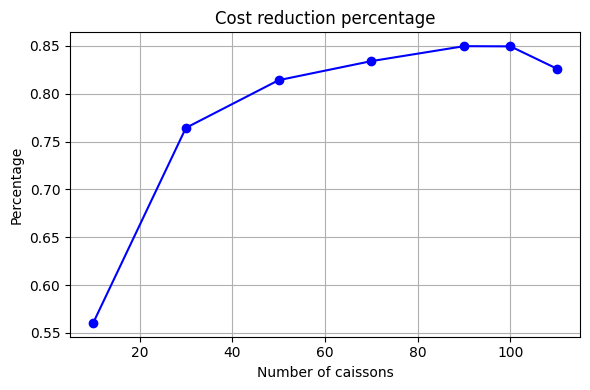

In [56]:
# cost reduction percentage plot for different number of caissons
# T = 180 Cmax = 10
import matplotlib.pyplot as plt

# 数据
caissons = [10, 30, 50, 70, 90, 100, 110]
reduction = [0.560483871,
             0.764361702,
             0.814195584,
             0.834116331,
             0.849741379,
             0.849533437,
             0.826234133]

# 绘图
plt.figure(figsize=(6, 4))
plt.plot(caissons, reduction, marker='o', linestyle='-', color='b')

plt.xlabel('Number of caissons')
plt.ylabel('Percentage')
plt.title('Cost reduction percentage')

plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
solutions = [
    {'name': 'A', 'groups': 48, 'cost': 6014},
    {'name': 'B', 'groups': 50,  'cost': 7930},
    {'name': 'C', 'groups': 62,  'cost': 9140},
    {'name': 'D', 'groups': 44,  'cost': 6719},
    {'name': 'E', 'groups': 52,  'cost': 7864},
    {'name': 'F', 'groups': 44,  'cost': 5161},
    {'name': 'G', 'groups': 44,  'cost': 5201},
    {'name': 'H', 'groups': 44,  'cost': 6014},
    {'name': 'I', 'groups': 110,  'cost': 11520},
    {'name': 'J', 'groups': 126,  'cost': 13065},
    {'name': 'F1', 'groups': 44,  'cost': 5161},
    {'name': 'F2', 'groups': 49,  'cost': 5325},
    {'name': 'F3', 'groups': 38,  'cost': 6183},
    {'name': 'F4', 'groups': 38,  'cost': 6111},
    {'name': 'F11', 'groups': 44,  'cost': 5161},
    {'name': 'F12', 'groups': 72,  'cost': 7720},
    {'name': 'F13', 'groups': 34,  'cost': 4698}
]

pareto = []

for i, s in enumerate(solutions):
    dominated = False
    for j, t in enumerate(solutions):
        if i == j:
            continue
        # t 支配 s 的条件（两个目标都是“越小越好”）
        if (t['groups'] <= s['groups'] and t['cost'] <= s['cost']) and \
           (t['groups'] <  s['groups'] or  t['cost']  <  s['cost']):
            dominated = True
            break
    if not dominated:
        pareto.append(s)

print("Pareto solutions:")
for s in pareto:
    print(s['name'], s['groups'], s['cost'])


Pareto solutions:
F13 34 4698


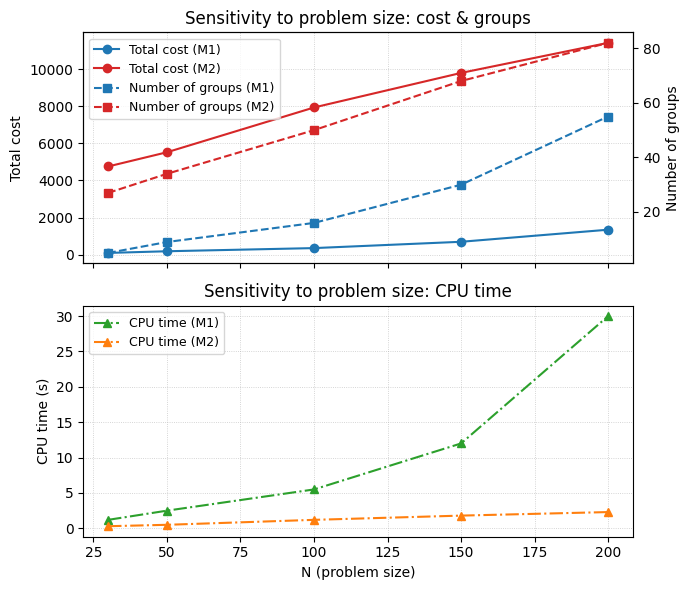

In [5]:
# sensitivity analysis for problem size:

import matplotlib.pyplot as plt
import numpy as np

# ===== 1. 数据 =====
N = np.array([30, 50, 100, 150, 200])

# M1
total_cost_M1 = np.array([100, 190, 360, 700, 1350])
num_groups_M1 = np.array([5, 9, 16, 30, 55])
cpu_time_M1   = np.array([1.2, 2.5, 5.5, 12.0, 30.0])  # 秒

# M2
total_cost_M2 = np.array([4755, 5520, 7930, 9790, 11410])
num_groups_M2 = np.array([27, 34, 50, 68, 82])
cpu_time_M2   = np.array([0.3, 0.5, 1.2, 1.8, 2.3])    # 秒

plt.rcParams["font.family"] = "DejaVu Sans"  # 若中文乱码可改成 "SimHei"

# ===== 2. 建两个子图 =====
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

# ---------- 子图 1：Total cost & Number of groups ----------
# 左轴：Total cost
line_cost_M1, = ax1.plot(
    N, total_cost_M1, color="#1f77b4", marker="o", linestyle="-",
    label="Total cost (M1)"
)
line_cost_M2, = ax1.plot(
    N, total_cost_M2, color="#d62728", marker="o", linestyle="-",
    label="Total cost (M2)"
)

# 右轴：Number of groups
ax1b = ax1.twinx()
line_groups_M1, = ax1b.plot(
    N, num_groups_M1, color="#1f77b4", marker="s", linestyle="--",
    label="Number of groups (M1)"
)
line_groups_M2, = ax1b.plot(
    N, num_groups_M2, color="#d62728", marker="s", linestyle="--",
    label="Number of groups (M2)"
)

ax1.set_ylabel("Total cost")
ax1b.set_ylabel("Number of groups")
ax1.set_title("Sensitivity to problem size: cost & groups")

# 合并图例（放在上子图）
lines = [line_cost_M1, line_cost_M2, line_groups_M1, line_groups_M2]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left", fontsize=9)

ax1.grid(True, which="both", linestyle=":", linewidth=0.6, alpha=0.7)

# ---------- 子图 2：CPU time ----------
line_cpu_M1, = ax2.plot(
    N, cpu_time_M1, color="#2ca02c", marker="^", linestyle="-.",
    label="CPU time (M1)"
)
line_cpu_M2, = ax2.plot(
    N, cpu_time_M2, color="#ff7f0e", marker="^", linestyle="-.",
    label="CPU time (M2)"
)

ax2.set_xlabel("N (problem size)")
ax2.set_ylabel("CPU time (s)")
ax2.set_title("Sensitivity to problem size: CPU time")

# 如需看线性 / 次线性，也可以把 CPU 轴改为对数：
# ax2.set_yscale("log")

ax2.legend(loc="upper left", fontsize=9)
ax2.grid(True, which="both", linestyle=":", linewidth=0.6, alpha=0.7)

fig.tight_layout()
plt.show()


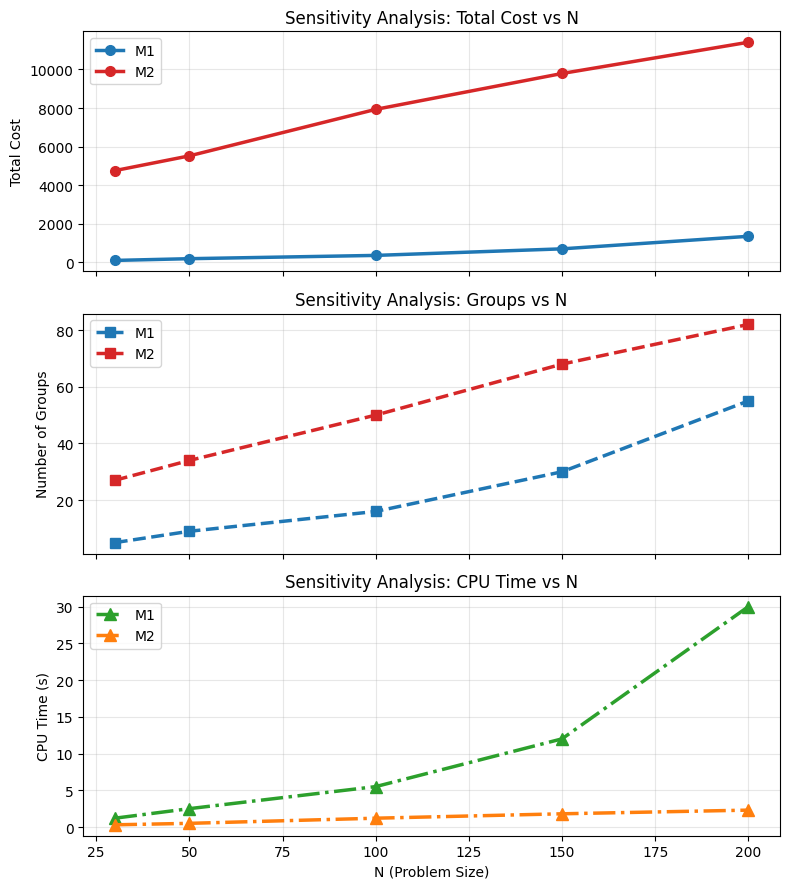

In [ ]:
# sensitivity analysis for problem size:
import matplotlib.pyplot as plt
import numpy as np

# ===== 数据 =====
N = np.array([30, 50, 100, 150, 200])

# M1
total_cost_M1 = np.array([100, 190, 360, 700, 1350])
num_groups_M1 = np.array([5, 9, 16, 30, 55])
cpu_time_M1   = np.array([1.2, 2.5, 5.5, 12.0, 30.0])

# M2
total_cost_M2 = np.array([4755, 5520, 7930, 9790, 11410])
num_groups_M2 = np.array([27, 34, 50, 68, 82])
cpu_time_M2   = np.array([0.3, 0.5, 1.2, 1.8, 2.3])

plt.rcParams["font.family"] = "DejaVu Sans"

# ===== 三个子图 =====
fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)

# ========== 图1：Total Cost ==========
axes[0].plot(N, total_cost_M1, "o-", color="#1f77b4", linewidth=2.5, markersize=7, label="M1")
axes[0].plot(N, total_cost_M2, "o-", color="#d62728", linewidth=2.5, markersize=7, label="M2")
axes[0].set_ylabel("Total Cost")
axes[0].set_title("Sensitivity Analysis: Total Cost vs N")
axes[0].legend(loc="upper left")
axes[0].grid(True, alpha=0.3)

# ========== 图2：Number of Groups ==========
axes[1].plot(N, num_groups_M1, "s--", color="#1f77b4", linewidth=2.5, markersize=7, label="M1")
axes[1].plot(N, num_groups_M2, "s--", color="#d62728", linewidth=2.5, markersize=7, label="M2")
axes[1].set_ylabel("Number of Groups")
axes[1].set_title("Sensitivity Analysis: Groups vs N")
axes[1].legend(loc="upper left")
axes[1].grid(True, alpha=0.3)

# ========== 图3：CPU Time ==========
axes[2].plot(N, cpu_time_M1, "^-.", color="#2ca02c", linewidth=2.5, markersize=8, label="M1")
axes[2].plot(N, cpu_time_M2, "^-.", color="#ff7f0e", linewidth=2.5, markersize=8, label="M2")
axes[2].set_xlabel("N (Problem Size)")
axes[2].set_ylabel("CPU Time (s)")
axes[2].set_title("Sensitivity Analysis: CPU Time vs N")
axes[2].legend(loc="upper left")
axes[2].grid(True, alpha=0.3)

# 可选：CPU 对数轴看线性度
# axes[2].set_yscale("log")

plt.tight_layout()
plt.show()
